# Анализ данных интернет-магазина. Исследование снижения конверсии

**Контекст:** интернет-магазин столкнулся со снижением конверсии.
В распоряжении есть данные за 12 месяцев: информация о пользователях, сессиях, заказах и товарах.

**Задача:** провести комплексный анализ пользовательского поведения, исследовать динамику ключевых продуктовых метрик и выявить возможные причины снижения конверсии.

**Цель**: сформулировать гипотезу о возможной причине снижения конверсии и предложить рекомендации по её проверке.

## 1. Обзор данных

### Импорт библиотек

In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Чтение файлов

In [99]:
base = "https://python-academy.org/static/product-analytics/dataset"

In [100]:
users = pd.read_csv(f"{base}/users.csv", parse_dates=["signup_date"])
products = pd.read_csv(f"{base}/products.csv")
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])
orders = pd.read_csv(f"{base}/orders.csv", parse_dates=["created_at"])

#### Таблица Users

In [101]:
users.head()

,user_id,signup_date,source,country,device_first,age_bucket,marketing_opt_in
0,u_00001,2026-04-04,paid_social,KZ,mobile,35-44,False
1,u_00002,2025-12-14,organic,RU,desktop,25-34,True
2,u_00003,2026-04-26,paid_social,RU,mobile,18-24,True
3,u_00004,2026-03-15,organic,AM,mobile,18-24,True
4,u_00005,2025-07-30,organic,RU,tablet,25-34,True


In [102]:
users.dtypes #проверка корректности типов данных для последующего анализа

user_id                        str
signup_date         datetime64[us]
source                         str
country                        str
device_first                   str
age_bucket                     str
marketing_opt_in              bool
dtype: object

In [103]:
users["source"].unique() #каналы привлечения

<ArrowStringArray>
['paid_social', 'organic', 'paid_search', 'referral', 'email']
Length: 5, dtype: str

#### Таблица Products

In [104]:
products.head()

,product_id,category,name,price_rub,in_stock
0,p_001,clothing,Куртка Lite 1,2050,True
1,p_002,clothing,Пальто Max 2,8700,True
2,p_003,clothing,Платье Pro 3,2500,True
3,p_004,clothing,Худи Classic 4,2850,True
4,p_005,clothing,Свитер Mini 5,6150,True


In [105]:
products.dtypes #проверка корректности типов данных для последующего анализа

product_id      str
category        str
name            str
price_rub     int64
in_stock       bool
dtype: object

In [106]:
products["category"].unique()

<ArrowStringArray>
['clothing', 'electronics', 'home', 'beauty', 'books', 'sports']
Length: 6, dtype: str

#### Таблица Sessions

In [107]:
sessions.head()

,session_id,user_id,started_at,duration_sec,device,source,country,pages_viewed,reached_step
0,s_000001,u_00001,2026-04-09 21:14:41,511,mobile,paid_social,KZ,9,home
1,s_000002,u_00001,2026-04-27 18:13:15,51,desktop,organic,KZ,5,product
2,s_000003,u_00001,2026-04-27 15:14:39,163,mobile,organic,KZ,1,product
3,s_000004,u_00002,2026-04-20 05:04:22,617,desktop,direct,RU,16,product
4,s_000005,u_00002,2026-01-08 14:42:20,249,mobile,organic,RU,13,product


In [108]:
sessions.dtypes #проверка корректности типов данных для последующего анализа

session_id                 str
user_id                    str
started_at      datetime64[us]
duration_sec             int64
device                     str
source                     str
country                    str
pages_viewed             int64
reached_step               str
dtype: object

In [109]:
print(sessions['source'].unique())
print(sessions['reached_step'].unique())

<ArrowStringArray>
['paid_social', 'organic', 'direct', 'paid_search', 'referral', 'email']
Length: 6, dtype: str
<ArrowStringArray>
['home', 'product', 'purchase', 'cart', 'checkout']
Length: 5, dtype: str


#### Таблица Orders

In [110]:
orders.head()

,order_id,user_id,session_id,created_at,total_rub,items_count,status
0,o_00001,u_00002,s_000007,2025-12-22 06:39:07,25150,2,completed
1,o_00002,u_00003,s_000013,2026-05-09 10:13:41,31650,2,completed
2,o_00003,u_00009,s_000046,2025-11-21 22:09:49,13900,1,completed
3,o_00004,u_00010,s_000052,2026-01-28 10:30:27,690,1,completed
4,o_00005,u_00013,s_000077,2026-03-16 15:57:24,2100,1,completed


In [111]:
orders.dtypes #проверка корректности типов данных для последующего анализа

order_id                  str
user_id                   str
session_id                str
created_at     datetime64[us]
total_rub               int64
items_count             int64
status                    str
dtype: object

#### Количество строк в таблицах

In [112]:
print(f"users:    {len(users):>7,}")
print(f"products: {len(products):>7,}")
print(f"sessions: {len(sessions):>7,}")
print(f"orders:   {len(orders):>7,}")

users:      6,000
products:     300
sessions:  68,668
orders:     7,327


Итог: данные лежат в четырёх CSV-файлах:

- users: зарегистрированные пользователи (дата регистрации, канал привлечения, страна, устройство при первом заходе)
- products: каталог из 300 товаров в 6 категориях
- sessions: визиты на сайт (время, устройство, конечный шаг воронки)
- orders: заказы (дата создания, сумма заказа, количество товаров и статус заказа)

#### Период покрытия данных

In [113]:
print(f"users:    {users['signup_date'].min().date()} - {users['signup_date'].max().date()}")
print(f"sessions: {sessions['started_at'].min().date()} - {sessions['started_at'].max().date()}")
print(f"orders:   {orders['created_at'].min().date()} - {orders['created_at'].max().date()}")

users:    2025-06-01 - 2026-05-31
sessions: 2025-06-01 - 2026-05-31
orders:   2025-06-01 - 2026-06-01


Период покрытия - 12 месяцев: июнь 2025 - май 2026. 

1 июня один заказ оформили после полуночи (в сессии, начавшейся вечером 31 мая)

#### Проверка на пропуски

Были найдены пропуски в двух таблицах:

In [114]:
print(users.isna().sum())

user_id               0
signup_date           0
source                0
country               0
device_first          0
age_bucket          309
marketing_opt_in      0
dtype: int64


In [115]:
print(sessions.isna().sum())

session_id         0
user_id            0
started_at         0
duration_sec       0
device             0
source             0
country         2078
pages_viewed       0
reached_step       0
dtype: int64


- age_bucket пропущен у 309 пользователей (~5%) (не указан возраст)
- country пропущена у 2078 сессий (~3%) (не указана страна)

#### Проверка на наличие отрицательных значений

In [116]:
print("Отрицательная длительность сессии:",
      (sessions["duration_sec"] < 0).sum())

print("Нулевые просмотры:",
      (sessions["pages_viewed"] <= 0).sum())

print("Нулевая или отрицательная сумма заказа:",
      (orders["total_rub"] <= 0).sum())

print("Нулевое или отрицательное количество товаров:",
      (orders["items_count"] <= 0).sum())

Отрицательная длительность сессии: 0
Нулевые просмотры: 0
Нулевая или отрицательная сумма заказа: 0
Нулевое или отрицательное количество товаров: 0


#### Проверка на связность таблиц

In [117]:
print(
    "Сессии без пользователя:",
    (~sessions["user_id"].isin(users["user_id"])).sum()
)

print(
    "Заказы без пользователя:",
    (~orders["user_id"].isin(users["user_id"])).sum()
)

print(
    "Заказы без сессии:",
    (~orders["session_id"].isin(sessions["session_id"])).sum()
)

Сессии без пользователя: 0
Заказы без пользователя: 0
Заказы без сессии: 0


#### Проверка на дубли

In [118]:
tables = {
    "users": users,
    "products": products,
    "sessions": sessions,
    "orders": orders
}

for name, table in tables.items():
    print(f"\n{name}")
    print("Полные дубли:", table.duplicated().sum())


users
Полные дубли: 0

products
Полные дубли: 0

sessions
Полные дубли: 0

orders
Полные дубли: 0


In [119]:
print(f"дублей user_id:     {users['user_id'].duplicated().sum()}")
print(f"дублей session_id:  {sessions['session_id'].duplicated().sum()}") 
print(f"дублей order_id:    {orders['order_id'].duplicated().sum()}") 
print(f"дублей products_id: {products['product_id'].duplicated().sum()}") 

дублей user_id:     0
дублей session_id:  8
дублей order_id:    0
дублей products_id: 0


In [120]:
sessions[sessions['session_id'].duplicated()]

,session_id,user_id,started_at,duration_sec,device,source,country,pages_viewed,reached_step
21333,s_008233,u_01822,2026-05-10 09:09:30,170,mobile,paid_social,PL,3,product
24954,s_024955,u_02158,2026-05-07 12:51:12,211,mobile,organic,US,5,product
28799,s_028800,u_02492,2025-12-14 08:03:25,185,desktop,email,BY,19,product
37187,s_037188,u_03213,2026-04-14 05:28:10,156,mobile,organic,KZ,18,product
49276,s_049277,u_04306,2025-10-19 16:42:05,309,mobile,paid_search,UA,9,purchase
51790,s_047284,u_04516,2026-05-04 21:51:50,143,mobile,organic,KZ,3,product
56511,s_056512,u_04918,2026-03-18 07:28:43,388,desktop,paid_search,RU,23,home
67444,s_065663,u_05899,2026-03-09 07:19:23,62,desktop,paid_social,UA,15,product


In [121]:
sessions[sessions['session_id']=='s_008233']

,session_id,user_id,started_at,duration_sec,device,source,country,pages_viewed,reached_step
8232,s_008233,u_00687,2026-03-16 01:17:21,236,desktop,email,BY,23,purchase
21333,s_008233,u_01822,2026-05-10 09:09:30,170,mobile,paid_social,PL,3,product


In [122]:
print("Повторяющиеся session_id:",
      sessions["session_id"].duplicated().sum())

print("Повторяющиеся пары user_id + session_id:",
      sessions.duplicated(["user_id", "session_id"]).sum())

# Посмотрим все записи с повторяющимися session_id
duplicate_ids = sessions.loc[
    sessions["session_id"].duplicated(keep=False),
    "session_id"
].unique()

sessions[
    sessions["session_id"].isin(duplicate_ids)
].sort_values(["session_id", "started_at"])

Повторяющиеся session_id: 8
Повторяющиеся пары user_id + session_id: 0


,session_id,user_id,started_at,duration_sec,device,source,country,pages_viewed,reached_step
8232,s_008233,u_00687,2026-03-16 01:17:21,236,desktop,email,BY,23,purchase
21333,s_008233,u_01822,2026-05-10 09:09:30,170,mobile,paid_social,PL,3,product
7592,s_024955,u_00638,2026-04-15 13:30:15,127,mobile,paid_search,UA,9,product
24954,s_024955,u_02158,2026-05-07 12:51:12,211,mobile,organic,US,5,product
28799,s_028800,u_02492,2025-12-14 08:03:25,185,desktop,email,BY,19,product
7300,s_028800,u_00618,2026-01-10 18:30:07,895,desktop,organic,RU,23,product
37187,s_037188,u_03213,2026-04-14 05:28:10,156,mobile,organic,KZ,18,product
7063,s_037188,u_00598,2026-05-15 02:15:26,129,mobile,paid_social,RU,3,purchase
47283,s_047284,u_04137,2026-01-23 08:54:12,113,desktop,paid_search,US,4,product
51790,s_047284,u_04516,2026-05-04 21:51:50,143,mobile,organic,KZ,3,product


Обнаружено 8 повторяющихся значений session_id. Проверка показала, что повторение идентификатора само по себе не означает дублирование сессии: один session_id может встречаться у разных пользователей. Для проверки уникальности и связывания заказов необходимо использовать составной ключ user_id + session_id.

#### Основные статистические показатели

In [123]:
print(orders["total_rub"].describe())

count      7327.000000
mean      34012.965743
std       34653.869367
min         230.000000
25%        8650.000000
50%       21900.000000
75%       47100.000000
max      243400.000000
Name: total_rub, dtype: float64


- заказы от 230 руб. до 243 400 руб.
- медиана ~22 000 руб.
- среднее ~34 000 руб.

Среднее в полтора раза больше медианы. 

Максимум в пять раз выше 75-го перцентиля -> несколько крупных заказов вытягивают среднее вверх: у суммы заказа длинный правый хвост

### Итог

Промежуточные выводы: 

- 12 месяцев истории
- 6 тысяч пользователей
- 7 тысяч заказов
- 70 тысяч сессий
- Пятишаговая воронка: home - product - cart - checkout - purchase
- В данных есть пропуски country и age_bucket
- Есть несколько дублей сессий
- Есть заказы с длинным хвостом по сумме

## 2. Анализ данных

1. ~5% заказов отменяется или возвращается:

In [124]:
print(f"доля завершённых: {(orders['status'] == 'completed').mean():.1%}")

доля завершённых: 95.3%


2. Больше половины трафика интернет-магазина (58%) приходит с мобильных устройств:

In [125]:
print(f"доля мобильных сессий: {(sessions['device'] == 'mobile').mean():.1%}")

доля мобильных сессий: 57.9%


3. Каждый четвёртый пользователь пришёл из органического трафика, остальные из платных и партнёрских каналов:

In [126]:
print((users["source"].value_counts(normalize=True) * 100).round(1))

source
paid_social    34.7
organic        25.0
paid_search    20.7
email           9.9
referral        9.6
Name: proportion, dtype: float64


4. Отмены и возвраты: 12,6 млн руб. (~5% от общей стоимости всех заказов):

In [127]:
print(orders.groupby("status").agg(
    orders=("order_id", "count"),     
    revenue=("total_rub", "sum"),
    avg_order=("total_rub", "mean"),
).round(0))

           orders    revenue  avg_order
status                                 
cancelled     205    7136750    34813.0
completed    6986  236572460    33864.0
returned      136    5503790    40469.0


5. Возвращённые заказы в среднем дороже завершенных.

6. Число заказов растет каждый месяц:

In [128]:
orders.groupby(orders["created_at"].dt.to_period("M")).size()

created_at
2025-06      13
2025-07      45
2025-08      90
2025-09     136
2025-10     230
2025-11     384
2025-12     468
2026-01     576
2026-02     664
2026-03    1025
2026-04    1267
2026-05    2427
2026-06       2
Freq: M, dtype: int64

7. Выручка по странам распределена следующим образом:

In [129]:
merged = orders.merge(users[["user_id", "country"]], on="user_id")

print(f"до:    {orders.shape}")
print(f"после: {merged.shape}") #проверка корректности объединения таблиц

до:    (7327, 7)
после: (7327, 8)


In [130]:
merged[["order_id", "user_id", "total_rub", "status", "country"]].head()

,order_id,user_id,total_rub,status,country
0,o_00001,u_00002,25150,completed,RU
1,o_00002,u_00003,31650,completed,RU
2,o_00003,u_00009,13900,completed,UA
3,o_00004,u_00010,690,completed,RU
4,o_00005,u_00013,2100,completed,US


In [131]:
completed = merged[merged["status"] == "completed"]
revenue = completed.groupby("country")["total_rub"].sum().sort_values(ascending=False)
print((revenue / 1e6).round(1)) #в миллионах

country
RU    118.0
KZ     36.5
BY     22.8
UA     12.3
US     12.2
DE     10.5
PL      7.4
TR      7.2
AM      5.4
GE      4.2
Name: total_rub, dtype: float64


Наибольшая выручка по России - 118 млн руб. (49,9% от всей выручки).

8. У 38% зарегистрированных пользователей нет ни одного заказа:

In [132]:
left = users.merge(orders[["user_id", "order_id"]], on="user_id", how="left")
print(f"пользователей без заказов: {left['order_id'].isna().sum()}")

пользователей без заказов: 2303


In [133]:
buyers = orders["user_id"].nunique()
print(f"покупателей: {buyers} из {len(users)} ({buyers / len(users):.1%})")

покупателей: 3697 из 6000 (61.6%)


9. Выручка по месяцам:

In [134]:
completed = orders[orders["status"] == "completed"]
monthly = completed.set_index("created_at")["total_rub"].resample("ME").sum()
print((monthly / 1e6).round(1))

created_at
2025-06-30     0.3
2025-07-31     1.1
2025-08-31     3.4
2025-09-30     4.3
2025-10-31     8.9
2025-11-30    12.5
2025-12-31    15.5
2026-01-31    18.0
2026-02-28    20.7
2026-03-31    31.2
2026-04-30    40.6
2026-05-31    80.0
2026-06-30     0.0
Freq: ME, Name: total_rub, dtype: float64


10. Количество заказов на сто сессий в каждом месяце:

In [135]:
om = orders.groupby(orders["created_at"].dt.to_period("M")).size()
sm = sessions.groupby(sessions["started_at"].dt.to_period("M")).size()
print((om / sm * 100).round(1))

created_at
2025-06    11.3
2025-07     9.9
2025-08    11.5
2025-09     9.9
2025-10    11.1
2025-11    13.2
2025-12    11.5
2026-01    11.5
2026-02    11.6
2026-03    11.3
2026-04     9.9
2026-05    10.0
2026-06     NaN
Freq: M, dtype: float64


Общие заказы растут, но на каждые 100 визитов магазин стал получать заметно меньше заказов, начиная с апреля.
Допущения: числитель включает все заказы, в том числе отменённые и возвращённые; знаменатель содержит все сессии; заказ может быть создан в другом календарном месяце относительно сессии.

**Промежуточные итоги:**

- 58% сессий - с мобильных устройств
- 12,6 млн руб. в отменах и возвратах, дорогие заказы возвращают чаще
- 38% пользователей ни разу не покупали
- 50% выручки из России;
- С апреля заказов на сессию стало меньше на ~12%

## 3. Анализ метрик

### DAU, MAU

Активные пользователи за май (по визитам и по покупкам):

In [136]:
may_visit = sessions[
    (sessions["started_at"] >= "2026-05-01") & (sessions["started_at"] < "2026-06-01")
]["user_id"].nunique()
may_buy = orders[
    (orders["created_at"] >= "2026-05-01") & (orders["created_at"] < "2026-06-01")
]["user_id"].nunique()
print(f"по визитам: {may_visit}, по покупкам: {may_buy}")

по визитам: 4822, по покупкам: 1610


MAU по месяцам:

In [137]:
s = sessions.set_index("started_at")
mau = s.resample("ME")["user_id"].nunique()
mau

started_at
2025-06-30      81
2025-07-31     261
2025-08-31     452
2025-09-30     733
2025-10-31    1087
2025-11-30    1446
2025-12-31    1927
2026-01-31    2168
2026-02-28    2556
2026-03-31    3294
2026-04-30    3970
2026-05-31    4822
Freq: ME, Name: user_id, dtype: int64

### Sticky factor

In [138]:
dau = sessions.set_index("started_at").resample("D")["user_id"].nunique()

In [139]:
sticky = (dau.resample("ME").mean() / mau * 100).round(1)
print(sticky)

started_at
2025-06-30     4.7
2025-07-31     5.5
2025-08-31     5.4
2025-09-30     6.1
2025-10-31     6.0
2025-11-30     6.5
2025-12-31     6.6
2026-01-31     7.2
2026-02-28     7.6
2026-03-31     8.4
2026-04-30     9.9
2026-05-31    12.9
Freq: ME, Name: user_id, dtype: float64


**Промежуточные выводы:**

- «активный по визитам» и «активный по покупкам» различаются втрое
- в мае sticky factor 12.9% 
- вовлечённость не падает

При этом заказов на сессию с апреля меньше.
Люди приходят, но не доходят до покупки. 

Есть предположение, что проблема внутри пути от визита к заказу.

### Конверсия

Доля сессий, закончившихся покупкой (за весь год):

In [140]:
print(f"{(sessions['reached_step'] == 'purchase').mean():.1%}")

10.7%


Посчитаем конверсии между соседними шагами:

In [141]:
reached_cart = sessions["reached_step"].isin(["cart", "checkout", "purchase"])
reached_checkout = sessions["reached_step"].isin(["checkout", "purchase"])
reached_purchase = sessions["reached_step"] == "purchase"

print(f"корзина -> оформление: {reached_checkout.sum() / reached_cart.sum():.1%}")
print(f"оформление -> покупка: {reached_purchase.sum() / reached_checkout.sum():.1%}")

корзина -> оформление: 63.0%
оформление -> покупка: 79.5%


Конверсия в покупку (от регистрации до первой покупки):

In [142]:
completed_orders = orders[orders["status"] == "completed"].copy()

first_order = (
    completed_orders
    .groupby("user_id")["created_at"]
    .min()
    .rename("first_order"))

u = users.merge(
    first_order,
    on="user_id",
    how="left")

u["days_to_purchase"] = (u["first_order"] - u["signup_date"]).dt.days

valid_purchase = (u["first_order"].notna() & (u["days_to_purchase"] >= 0))

print(f"Доля пользователей с завершённой покупкой: " 
      f"{valid_purchase.mean():.1%}")

print(f"Покупка в первые 14 дней: "
      f"{(valid_purchase & (u['days_to_purchase'] <= 14)).mean():.1%}")

print(f"Медиана дней до первой покупки: "
      f"{u.loc[valid_purchase, 'days_to_purchase'].median():.0f}")

Доля пользователей с завершённой покупкой: 60.0%
Покупка в первые 14 дней: 17.6%
Медиана дней до первой покупки: 36


**Итог:**

- Сессия -> покупка: 10.7% (упала с апреля)
- Корзина -> оформление: 63.0%
- Оформление -> покупка: 79.5%
- Пользователь -> покупатель: 60% за всё время, 17,6% за первые 14 дней
- Медиана дней до первой покупки - 36 дней

### Средний и медианный чек

In [143]:
completed = orders[orders["status"] == "completed"]

print(f"средний чек: {completed['total_rub'].mean():.0f}")

print(f"медианный чек: {completed['total_rub'].median():.0f}")

средний чек: 33864
медианный чек: 21800


В завершенных заказах разрыв тот же, что и разрыв во всех заказах: среднее в полтора раза выше медианы.

### Квантили

In [144]:
print(completed["total_rub"].quantile([0.25, 0.5, 0.75, 0.9, 0.99]).round(0))

0.25      8478.0
0.50     21800.0
0.75     46812.0
0.90     89800.0
0.99    145100.0
Name: total_rub, dtype: float64


- четверть заказов дешевле 8 478 руб.
- половина дешевле 21 800 руб.
- один заказ из ста дороже 145 тысяч.

Распределение сильно вытянуто вправо.

Доля выручки от десятой части самых дорогих заказов:

In [145]:
t = completed["total_rub"]
threshold = t.quantile(0.9)
share = t[t >= threshold].sum() / t.sum()
print(f"топ-10% заказов (дороже {threshold:.0f}) дают {share:.1%} выручки")

топ-10% заказов (дороже 89800) дают 33.6% выручки


In [146]:
monthly_aov = completed.set_index("created_at")["total_rub"].resample("ME").mean().round(0)
print(monthly_aov)

created_at
2025-06-30    28461.0
2025-07-31    28312.0
2025-08-31    39426.0
2025-09-30    33019.0
2025-10-31    40957.0
2025-11-30    33957.0
2025-12-31    34443.0
2026-01-31    32959.0
2026-02-28    32573.0
2026-03-31    32045.0
2026-04-30    33479.0
2026-05-31    34585.0
2026-06-30     7400.0
Freq: ME, Name: total_rub, dtype: float64


### ARPU

In [147]:
rev_m = completed.set_index("created_at")["total_rub"].resample("ME").sum()
mau_m = sessions.set_index("started_at").resample("ME")["user_id"].nunique()
print((rev_m / mau_m).round(0).tail(5))

created_at
2026-02-28     8080.0
2026-03-31     9466.0
2026-04-30    10238.0
2026-05-31    16582.0
2026-06-30        NaN
Freq: ME, dtype: float64


Средняя выручка на пользователя возросла.

In [148]:
def arpu_parts(ym):
    s = sessions[sessions["started_at"].dt.to_period("M").astype(str) == ym]
    c = completed[completed["created_at"].dt.to_period("M").astype(str) == ym]
    mau = s["user_id"].nunique()
    print(f"{ym}: визитов на активного {len(s) / mau:.2f} "
          f"× конверсия {len(c) / len(s):.1%} × чек {c['total_rub'].mean():.0f} "
          f"= {c['total_rub'].sum() / mau:.0f}")

arpu_parts("2026-03")
arpu_parts("2026-04")
arpu_parts("2026-05")

2026-03: визитов на активного 2.76 × конверсия 10.7% × чек 32045 = 9466
2026-04: визитов на активного 3.23 × конверсия 9.5% × чек 33479 = 10238
2026-05: визитов на активного 5.03 × конверсия 9.5% × чек 34585 = 16582


Рост ARPU с марта по май обусловлен прежде всего увеличением частоты визитов на активного пользователя, а также умеренным ростом среднего чека. При этом конверсия визита в завершённый заказ снизилась с 10,7% до 9,5%. Таким образом, рост активности и среднего чека компенсировал отрицательную динамику конверсии.

### Выручка на пользователя и покупателя


In [149]:
print(f"на зарегистрированного: {completed['total_rub'].sum() / len(users):.0f}")

print(f"на покупателя: {completed['total_rub'].sum() / completed['user_id'].nunique():.0f}")

на зарегистрированного: 39429
на покупателя: 65678


Промежуточные выводы:

- трафик и вовлечённость выросли
- чек стабилен
- деньги на пользователя выросли 
- конверсия визита в заказ снизилась

## 4. Когортный анализ

Количество визитов на пользователя за первые 14 дней жизни:

In [150]:
s = sessions.merge(users[["user_id", "signup_date"]], on="user_id")
s["age_days"] = (s["started_at"] - s["signup_date"]).dt.days
early = s[
    s["age_days"].between(0, 14)
].copy()
early["cohort"] = early["signup_date"].dt.to_period("M")

cohort_size = users.groupby(users["signup_date"].dt.to_period("M"))["user_id"].count()
print((early.groupby("cohort")["session_id"].count() / cohort_size).round(2))

cohort
2025-06    0.48
2025-07    0.63
2025-08    0.57
2025-09    0.71
2025-10    0.78
2025-11    0.90
2025-12    0.98
2026-01    1.29
2026-02    1.68
2026-03    2.29
2026-04    3.94
2026-05    9.27
Freq: M, dtype: float64


В более поздних когортах наблюдается увеличение количества сессий в первые 14 дней после регистрации.

In [151]:
early["is_purchase"] = early["reached_step"] == "purchase"
print((early.groupby("cohort")["is_purchase"].mean() * 100).round(1))

cohort
2025-06    10.7
2025-07    12.9
2025-08     8.4
2025-09     9.1
2025-10     9.0
2025-11    15.7
2025-12    11.1
2026-01    12.3
2026-02    12.7
2026-03    10.4
2026-04    10.3
2026-05     9.7
Freq: M, Name: is_purchase, dtype: float64


In [152]:
cohort_size

signup_date
2025-06    254
2025-07    321
2025-08    397
2025-09    419
2025-10    485
2025-11    557
2025-12    567
2026-01    309
2026-02    589
2026-03    689
2026-04    710
2026-05    703
Freq: M, Name: user_id, dtype: int64

Когорты, чьи первые недели пришлись на апрель и позже, конвертируют ранний визит примерно на пятую часть хуже.

#### Retention-матрица

Календарный retention по визитам:

In [153]:
users["cohort"] = users["signup_date"].dt.to_period("M")
s = sessions.merge(users[["user_id", "cohort"]], on="user_id")
s["month"] = s["started_at"].dt.to_period("M")
s["m"] = (s["month"] - s["cohort"]).apply(lambda d: d.n)

active = s.groupby(["cohort", "m"])["user_id"].nunique().unstack()
cohort_size = users.groupby("cohort")["user_id"].count()
retention = (active.div(cohort_size, axis=0) * 100).round(1)
retention.iloc[:, :7]

m,0,1,2,3,4,5,6
cohort,,,,,,,
2025-06,31.9,53.5,50.0,50.0,60.2,57.5,57.9
2025-07,38.9,59.8,62.3,65.4,60.4,62.6,62.6
2025-08,33.5,58.4,61.0,63.2,63.5,52.1,54.9
2025-09,41.5,63.7,66.1,66.8,67.3,63.5,65.9
2025-10,44.3,68.2,69.7,65.6,67.0,67.6,69.5
2025-11,44.3,75.4,72.9,69.7,73.6,72.9,74.3
2025-12,51.0,77.1,72.0,77.6,74.4,75.0,NaN
2026-01,58.6,78.6,80.3,80.9,79.3,NaN,NaN
2026-02,63.8,87.9,85.7,85.2,NaN,NaN,NaN


Матрица отражает retention по визитам - долю пользователей каждой месячной когорты, которые возвращались хотя бы с одним визитом в последующие месяцы. У более поздних когорт показатель первого месяца после регистрации выше: от 53,5% у когорты июня 2025 года до 96,2% у когорты апреля 2026 года. Однако последние когорты ещё не прошли полный период наблюдения, поэтому сравнивать их долгосрочный retention с более старыми когортами пока рано. 

**Вывод:** Когортный анализ показывает рост доли пользователей, возвращающихся на сайт в последующие месяцы после регистрации. У более поздних когорт показатель выше, чем у ранних, что может свидетельствовать об улучшении пользовательской активности. Однако сравнение ограничено неполным периодом наблюдения для новых когорт и особенностями расчёта retention по визитам. Поэтому делать вывод об улучшении удержания покупателей и повторных покупок только на основании этой матрицы нельзя.

## 5. Воронка покупки

За всё время:

In [154]:
steps = ["home", "product", "cart", "checkout", "purchase"]
counts = pd.Series(
    [sessions["reached_step"].isin(steps[i:]).sum() for i in range(len(steps))],
    index=steps,
)
print(counts)

home        68668
product     48753
cart        14631
checkout     9215
purchase     7327
dtype: int64


- всего 68 668 визитов
- 7 327 из них закончились покупкой

In [155]:
of_all = (counts / counts.iloc[0] * 100).round(1) #от всех
of_prev = (counts / counts.shift(1) * 100).round(1) #от предыдущего

От всех:

In [156]:
print(of_all)

home        100.0
product      71.0
cart         21.3
checkout     13.4
purchase     10.7
dtype: float64


От предыдущего шага:

In [157]:
print(of_prev)

home         NaN
product     71.0
cart        30.0
checkout    63.0
purchase    79.5
dtype: float64


Итог: 

- главная -> товар теряет 29% 
- товар -> корзина теряет 70%
- корзина -> оформление теряет 37%
- оформление -> покупка теряет 20%.

**Воронка по каналам привлечения:**

In [158]:
df = sessions.copy()
df["cart"] = df["reached_step"].isin(["cart", "checkout", "purchase"])
df["chk"] = df["reached_step"].isin(["checkout", "purchase"])

res = df.groupby("source").agg(cart=("cart", "sum"), chk=("chk", "sum"))
res["conv"] = (res["chk"] / res["cart"] * 100).round(1)
res

,cart,chk,conv
source,,,
direct,2576,1675,65.0
email,1622,1047,64.5
organic,4228,2730,64.6
paid_search,2074,1322,63.7
paid_social,2879,1639,56.9
referral,1252,802,64.1


In [159]:
df["is_mobile"] = df["device"] == "mobile"
print((df.groupby("source")["is_mobile"].mean() * 100).round(0))

source
direct         58.0
email          61.0
organic        50.0
paid_search    54.0
paid_social    70.0
referral       53.0
Name: is_mobile, dtype: float64


**Воронка для каждого устройства:**

In [160]:
funnel = pd.DataFrame({
    dev: [g["reached_step"].isin(steps[i:]).sum() for i in range(len(steps))]
    for dev, g in sessions.groupby("device")
}, index=steps)

(funnel / funnel.shift(1) * 100).round(1)

,desktop,mobile,tablet
home,NaN,NaN,NaN
product,70.7,71.1,71.5
cart,31.4,29.4,29.1
checkout,69.8,57.8,69.9
purchase,80.2,79.0,79.5


**Двумерный разрез**

*Корзина -> оформление* по каналам привлечения и устройствам:

In [161]:
res2 = df.groupby(["source", "device"]).agg(cart=("cart", "sum"), chk=("chk", "sum"))
res2["conv"] = (res2["chk"] / res2["cart"] * 100).round(1)
print(res2["conv"].unstack())

device       desktop  mobile  tablet
source                              
direct          72.7    59.1    74.3
email           70.9    60.0    73.1
organic         70.6    57.9    72.3
paid_search     68.6    60.0    66.5
paid_social     62.6    54.3    63.9
referral        71.5    57.9    66.1


**Промежуточные выводы**

- внутри каждого канала привлечения конверсия *корзина -> оформление* ниже у **мобильных устройств**
- у канала paid_social наблюдается более низкая конверсия на этапе корзина -> оформление по сравнению с другими каналами на всех типах устройств. При этом канал характеризуется высокой долей мобильного трафика.

### Шаг по месяцам и устройствам

In [162]:
df = sessions.copy()
df["ym"] = df["started_at"].dt.to_period("M")
df["cart"] = df["reached_step"].isin(["cart", "checkout", "purchase"])
df["chk"] = df["reached_step"].isin(["checkout", "purchase"])

g = df.groupby(["ym", "device"]).agg(cart=("cart", "sum"), chk=("chk", "sum"))
print((g["chk"] / g["cart"] * 100).round(1).unstack())

device   desktop  mobile  tablet
ym                              
2025-06     46.2    71.4    50.0
2025-07     75.0    61.4    77.8
2025-08     66.7    63.5    73.9
2025-09     71.7    59.6    64.9
2025-10     65.1    66.7    66.7
2025-11     71.5    73.9    70.3
2025-12     70.5    66.1    79.3
2026-01     70.8    66.2    70.4
2026-02     67.9    71.1    76.5
2026-03     68.7    68.3    68.1
2026-04     70.5    47.8    66.0
2026-05     70.2    50.0    70.0


**Вывод:** 

Первые месяцы выглядят более шумными: вероятно, на старте магазина было меньше пользователей, поэтому далее для сравнения рассматривается более зрелый период, начиная с ноября.

С апреля 2026 года конверсия из корзины в оформление на мобильных устройствах заметно снизилась. До апреля показатели разных устройств были близки, а после снижения мобильной конверсии показатели десктопа и планшетов остались относительно стабильными.

Это указывает на проблему, связанную с пользовательским сценарием на мобильных устройствах. Возможной причиной могут быть изменения мобильной версии магазина, затронувшие переход от корзины к оформлению заказа.

In [163]:
for dev in ["mobile", "desktop"]:
    d = df[df["device"] == dev]
    pre = d[d["ym"] < "2026-04"]
    post = d[d["ym"] >= "2026-04"]
    print(f"{dev}: до {pre['chk'].sum() / pre['cart'].sum() * 100:.1f}, "
          f"после {post['chk'].sum() / post['cart'].sum() * 100:.1f}")

mobile: до 68.1, после 49.2
desktop: до 69.2, после 70.3


Минус девятнадцать пунктов у одного устройства при стабильности другого.

**Что установлено по данным**

С апреля 2026 года конверсия шага корзина -> оформление на мобильных устройствах снизилась примерно с 68% до 49% (около 19 процентных пунктов). На десктопе сопоставимого снижения не наблюдается. Это совпадение указывает на возможную проблему в мобильном сценарии. Необходимо проверить: были ли изменения состава мобильного трафика, изменения рекламных кампаний, изменение мобильного интерфейса, технические проблемы.

**Допущение для пет-проекта**

Для дальнейшей проверки примем условие, что 1 апреля 2026 года команда выпустила редизайн мобильного чекаута. 

**Гипотеза**

Редизайн мобильного чекаута, выпущенный 1 апреля 2026, снизил конверсию шага корзина -> оформление на мобильных устройствах с ~68% до ~49%, то есть на 19 процентных пунктов.

In [164]:
df = sessions.copy()
df["ym"] = df["started_at"].dt.to_period("M")
mob_post = df[(df["device"] == "mobile") & (df["ym"] >= "2026-04")]
carts = mob_post["reached_step"].isin(["cart", "checkout", "purchase"]).sum()

lost_step = 0.681 - 0.492        # потерянная конверсия шага 
chk_to_purchase = 0.790          # оформление -> покупка на мобильных устройствах
aov = completed[completed["created_at"] >= "2026-04-01"]["total_rub"].mean()

lost_rub = carts * lost_step * chk_to_purchase * aov
print(f"мобильных корзин за апрель-май: {carts}")

print(f"недополученная выручка: {lost_rub / 1e6:.1f} млн ₽, или {lost_rub / 2 / 1e6:.1f} млн ₽ в месяц")

мобильных корзин за апрель-май: 4548
недополученная выручка: 23.2 млн ₽, или 11.6 млн ₽ в месяц


Оценка основана на предположении, что без изменения мобильной конверсии она сохранилась бы на уровне 68,1%. Расчёт также предполагает стабильность конверсии оформления в покупку и среднего чека. Поэтому 23,2 млн рублей - оценка потенциально недополученной выручки, а не фактический финансовый ущерб.

Визуализация:

In [165]:
df = sessions.copy()
df["ym"] = df["started_at"].dt.to_period("M").astype(str)
df["cart"] = df["reached_step"].isin(["cart", "checkout", "purchase"])
df["chk"] = df["reached_step"].isin(["checkout", "purchase"])
g = df.groupby(["ym", "device"]).agg(cart=("cart", "sum"), chk=("chk", "sum"))
conv = (g["chk"] / g["cart"] * 100).unstack().round(1)
print(conv.tail(3))

device   desktop  mobile  tablet
ym                              
2026-03     68.7    68.3    68.1
2026-04     70.5    47.8    66.0
2026-05     70.2    50.0    70.0


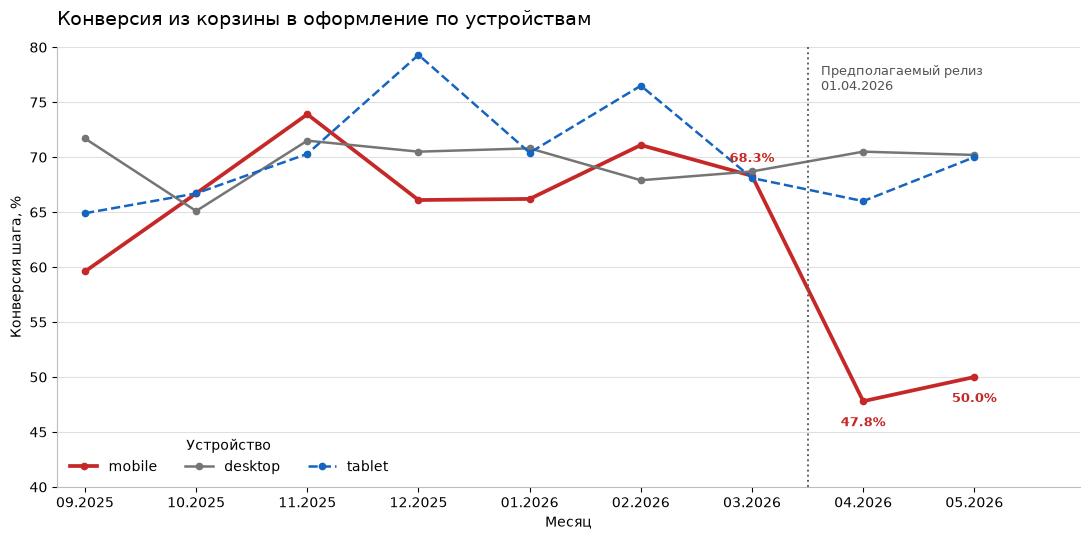

In [166]:
trimmed = conv.loc["2025-09":].copy()
months = trimmed.index.tolist()
x = list(range(len(months)))
fig, ax = plt.subplots(figsize=(11, 5.5))

series_style = {
    "mobile":  {"color": "#c62828", "linewidth": 2.7, "marker": "o", "linestyle": "-"},
    "desktop": {"color": "#757575", "linewidth": 1.8, "marker": "o", "linestyle": "-"},
    "tablet":  {"color": "#1565c0", "linewidth": 1.8, "marker": "o", "linestyle": "--"},
}

for device in ["mobile", "desktop", "tablet"]:
    ax.plot(
        x,
        trimmed[device].values,
        label=device,
        markersize=4.5,
        **series_style[device])

if "2026-04" in months:
    release_x = months.index("2026-04") - 0.5
    ax.axvline(release_x, color="#616161", linestyle=":", linewidth=1.4)
    ax.text(
        release_x + 0.12, 78.5,
        "Предполагаемый релиз\n01.04.2026",
        ha="left", va="top", color="#555555", fontsize=9)

for month, offset in [("2026-03", (0, 10)), ("2026-04", (0, -18)), ("2026-05", (0, -18))]:
    if month in months:
        xpos = months.index(month)
        value = trimmed.loc[month, "mobile"]
        ax.annotate(
            f"{value:.1f}%",
            (xpos, value),
            xytext=offset,
            textcoords="offset points",
            ha="center",
            fontsize=9,
            color="#c62828",
            fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{m[5:7]}.{m[:4]}" for m in months])

ax.set_title( "Конверсия из корзины в оформление по устройствам", loc="left", fontsize=14, pad=16)
ax.set_ylabel("Конверсия шага, %")
ax.set_xlabel("Месяц")
ax.set_ylim(40, 80)
ax.set_xlim(-0.25, len(x) - 0.05)
ax.grid(axis="y", color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(title="Устройство", frameon=False, ncol=3, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#bdbdbd")
plt.tight_layout()
plt.show()

**Что показывает график**
- До апреля 2026 года конверсия из корзины в оформление на мобильных и десктопных устройствах была примерно одинаковой.
- В апреле мобильная конверсия резко снизилась.
- В мае мобильная конверсия осталась на низком уровне и не вернулась к прежним значениям.
- Десктопная конверсия за тот же период оставалась относительно стабильной.

График показывает изменение конверсии во времени и различие между устройствами. Он поддерживает гипотезу о проблеме в мобильном сценарии, но не доказывает, что причиной стал редизайн. 

**Итоговые выводы**

В ходе анализа выявлено, что с апреля 2026 года снизилась конверсия интернет-магазина из корзины в оформление заказа. Наиболее заметное падение наблюдается на мобильных устройствах: показатель снизился примерно с 68% до 48-50%, тогда как на десктопах и планшетах существенных изменений не произошло.

Дополнительно установлено, что канал paid_social демонстрирует более низкую конверсию на этом этапе в сравнении с другими каналами привлечения.

Основная гипотеза исследования - возможная проблема в мобильном сценарии оформления заказа. В рамках учебного кейса предполагается, что снижение могло совпасть с редизайном мобильного чекаута 1 апреля 2026 года. 

**Рекомендации**: для проверки гипотезы необходимо проверить мобильную версию на технические ошибки и провести A/B-тестирование.